In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.preprocessing import StandardScaler
import json


In [ ]:
file_path = '../data/2_2_cleaned_data.csv'
data = pd.read_csv(file_path, sep=',')
data.info()

with open("../../config.json") as f:
    cfg = json.load(f)

rc_target = cfg['rc']
rf_target = cfg['rf']
target = cfg["target"]
file_name = cfg["file_name"]
random_state = cfg["split"]["random_state"]

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   ID                                 148 non-null    str    
 1   Dias curado                        148 non-null    float64
 2   Dosage 1 (Kg/m3)                   148 non-null    float64
 3   Dosage 2 (Kg/m3)                   148 non-null    float64
 4   % Celulosa 1                       148 non-null    float64
 5   % Celulosa 2                       148 non-null    float64
 6   Rf (MPa)                           148 non-null    float64
 7   Rc (MPa)                           148 non-null    float64
 8   Etalement t=0 (mm)                 148 non-null    float64
 9   Teneur en air (%)                  148 non-null    float64
 10  Masse volumique (Kg/m3)            148 non-null    float64
 11  Retrait                            148 non-null    float64
 12  Coef.

# 3. Statistical Analysis (EDA)

Text(0.5, 1.0, 'Distribution of Rf (MPa)')

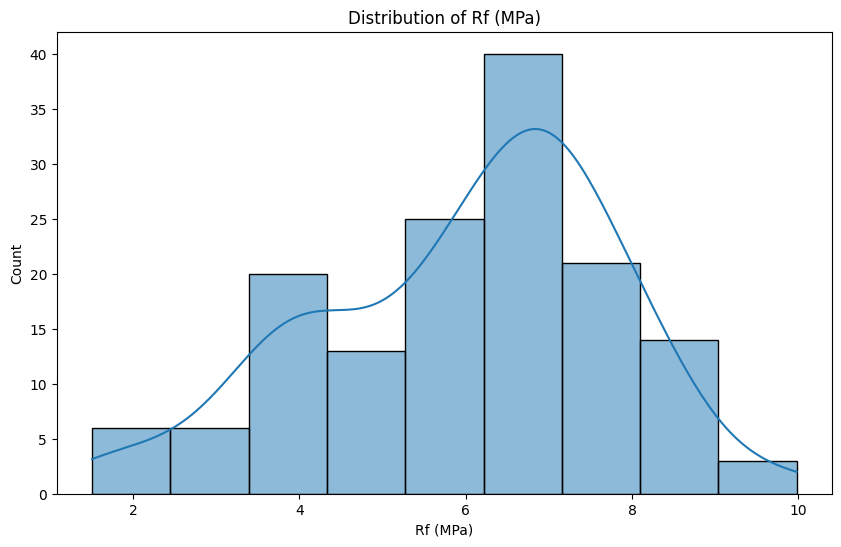

In [3]:
#Distribution of the target variable
plt.figure(figsize=(10, 6))
sns.histplot(data[target], kde=True)
plt.title(f'Distribution of {target}')

C:\Users\matte\AppData\Local\Temp\ipykernel_2144\3242116019.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(include=['object'])


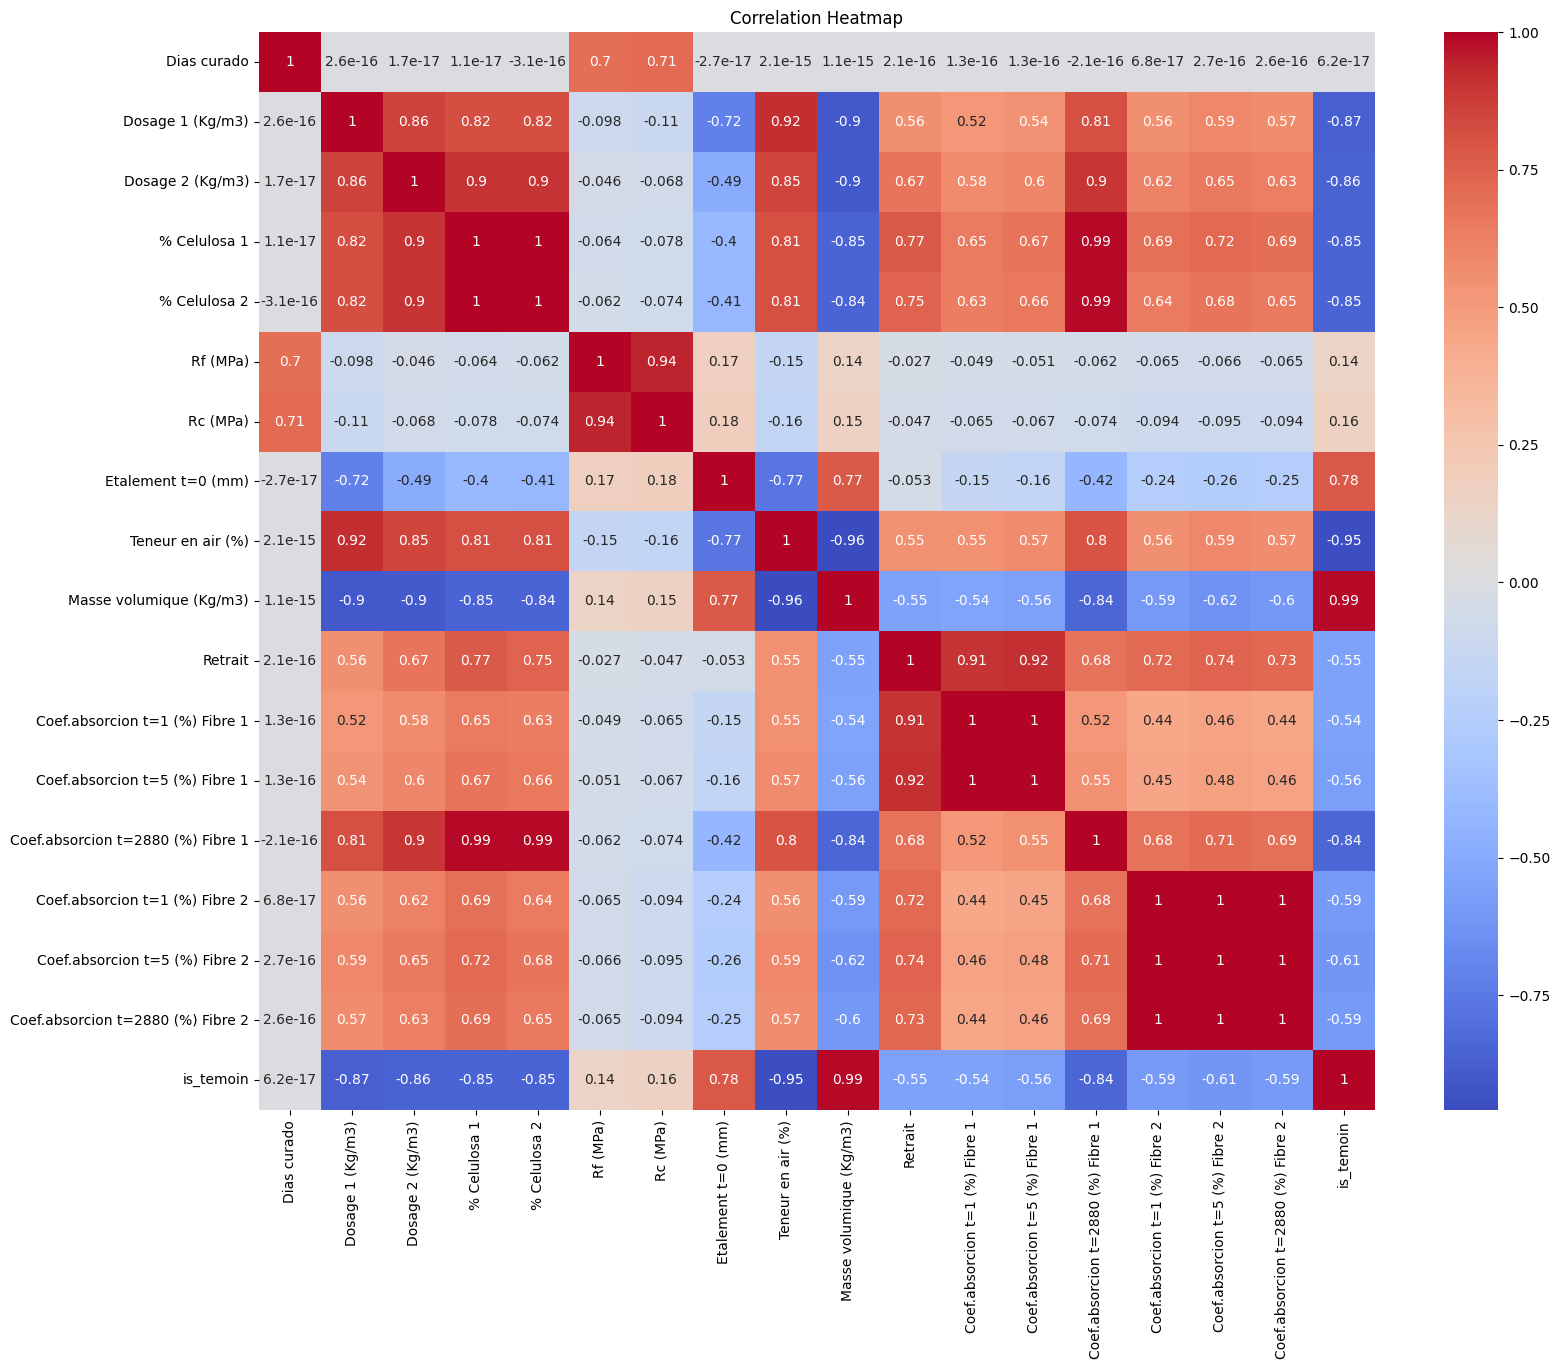

In [ ]:
numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
categorical_columns = data.select_dtypes(include=['object'])

# Correlation heatmap for numerical features
plt.figure(figsize=(18, 14))
sns.heatmap(data[numerical_columns].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

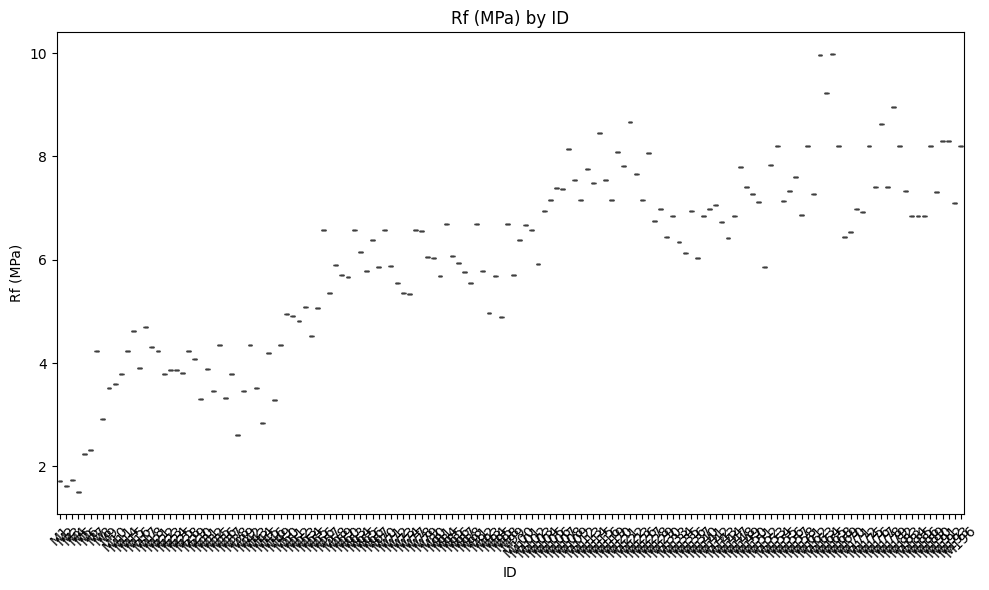

In [ ]:
for column in categorical_columns:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=data[column], y=data[target])
    plt.title(f'{target} by {column}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 3.2 Distribution of the Target Variable Across Discrete Numerical Features

Dias curado has 4 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

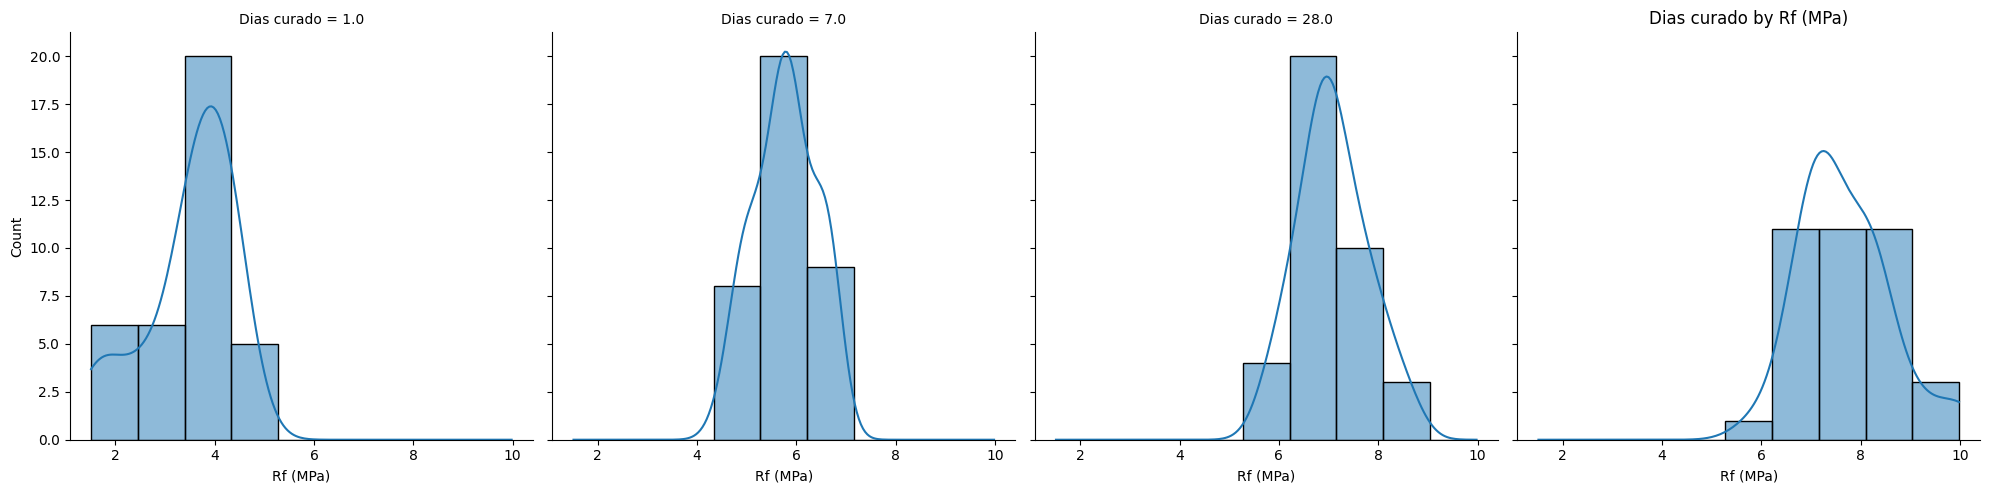

Dosage 1 (Kg/m3) has 5 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

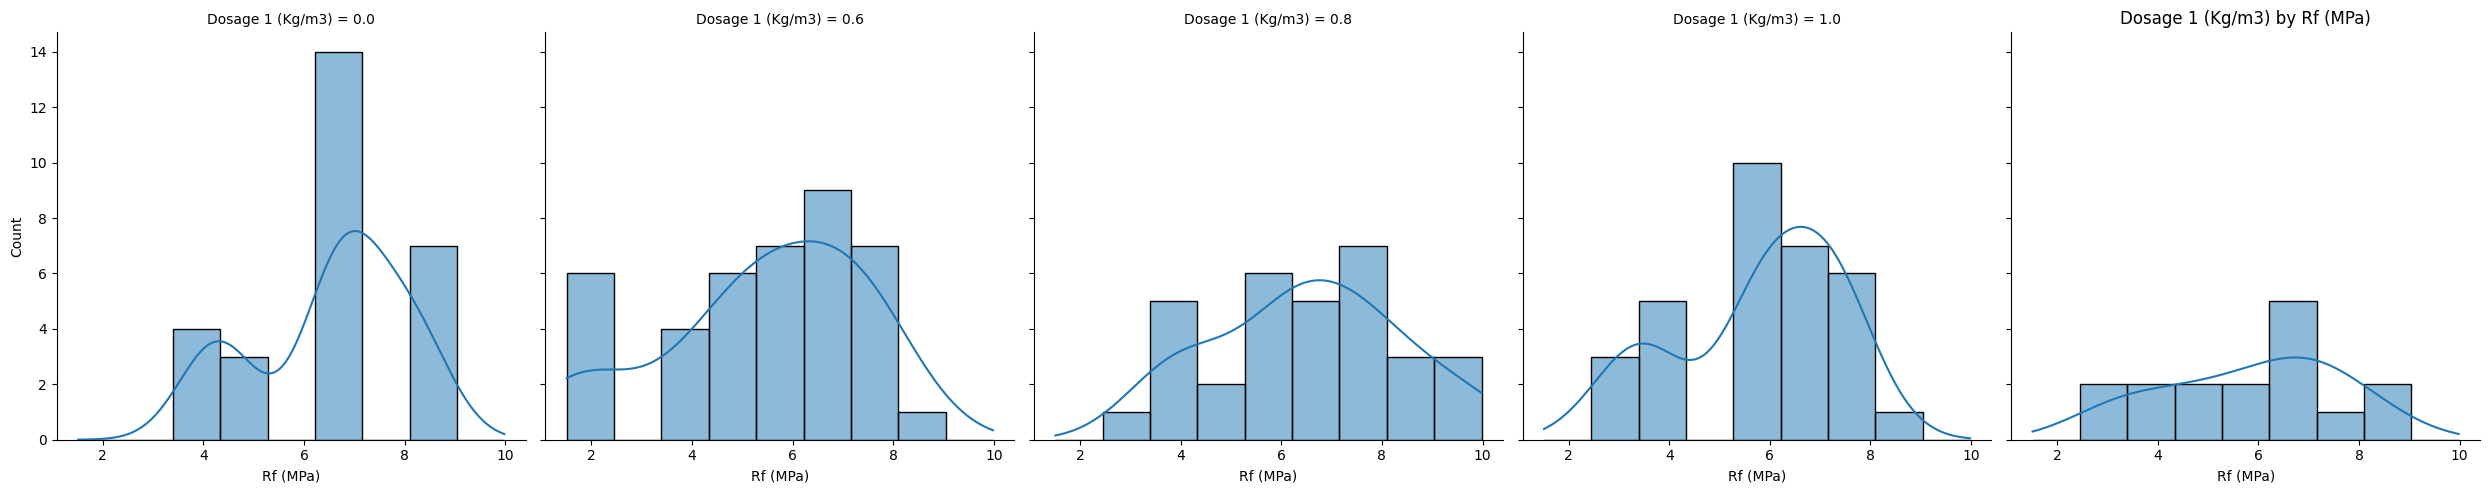

Dosage 2 (Kg/m3) has 8 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

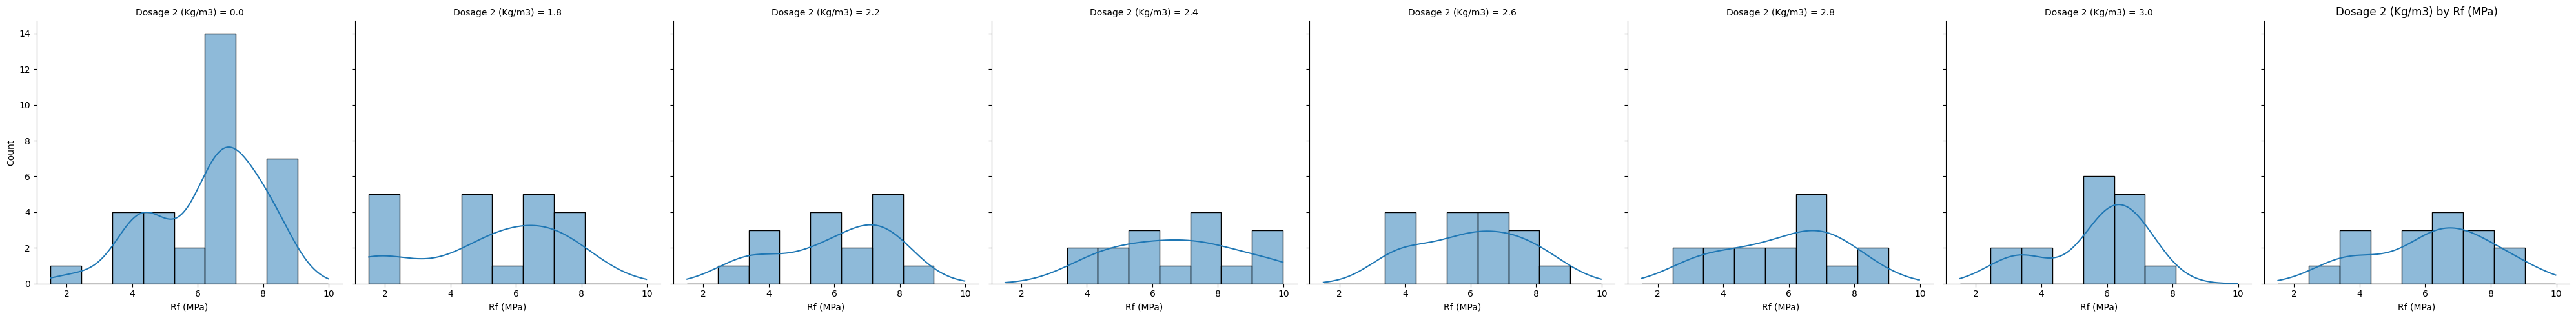

% Celulosa 1 has 3 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

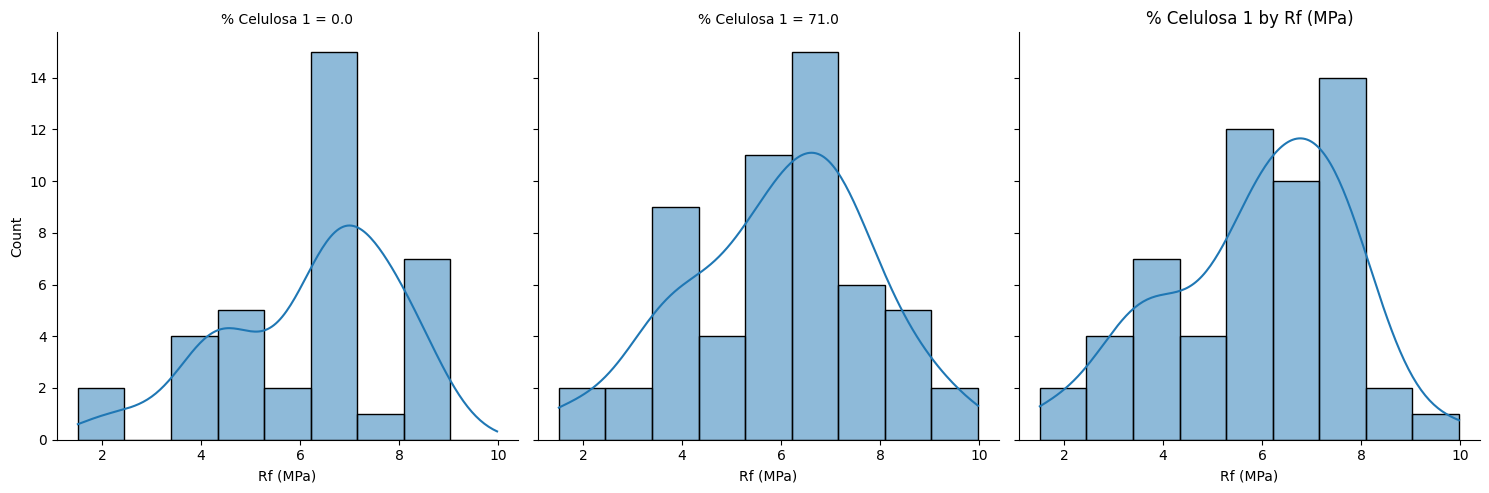

% Celulosa 2 has 3 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

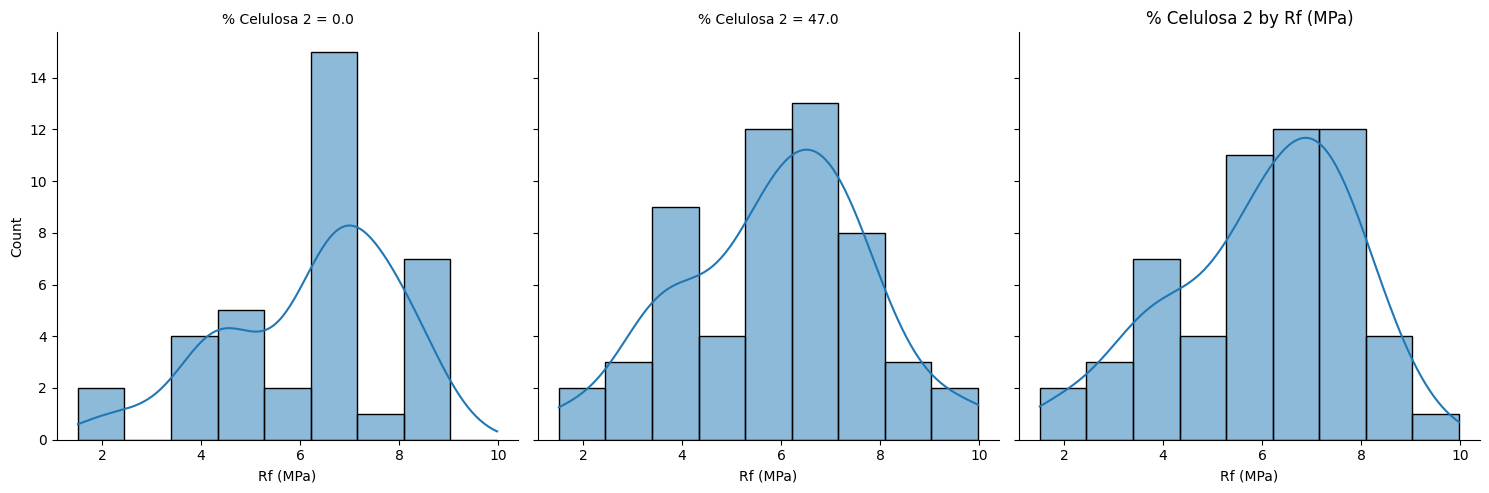

Teneur en air (%) has 11 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

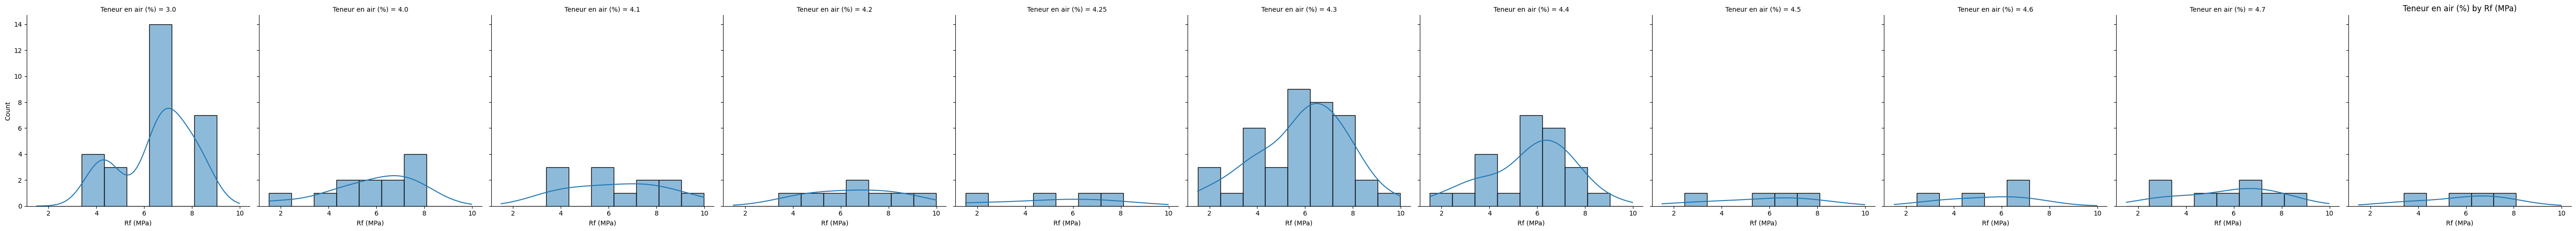

Retrait has 7 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

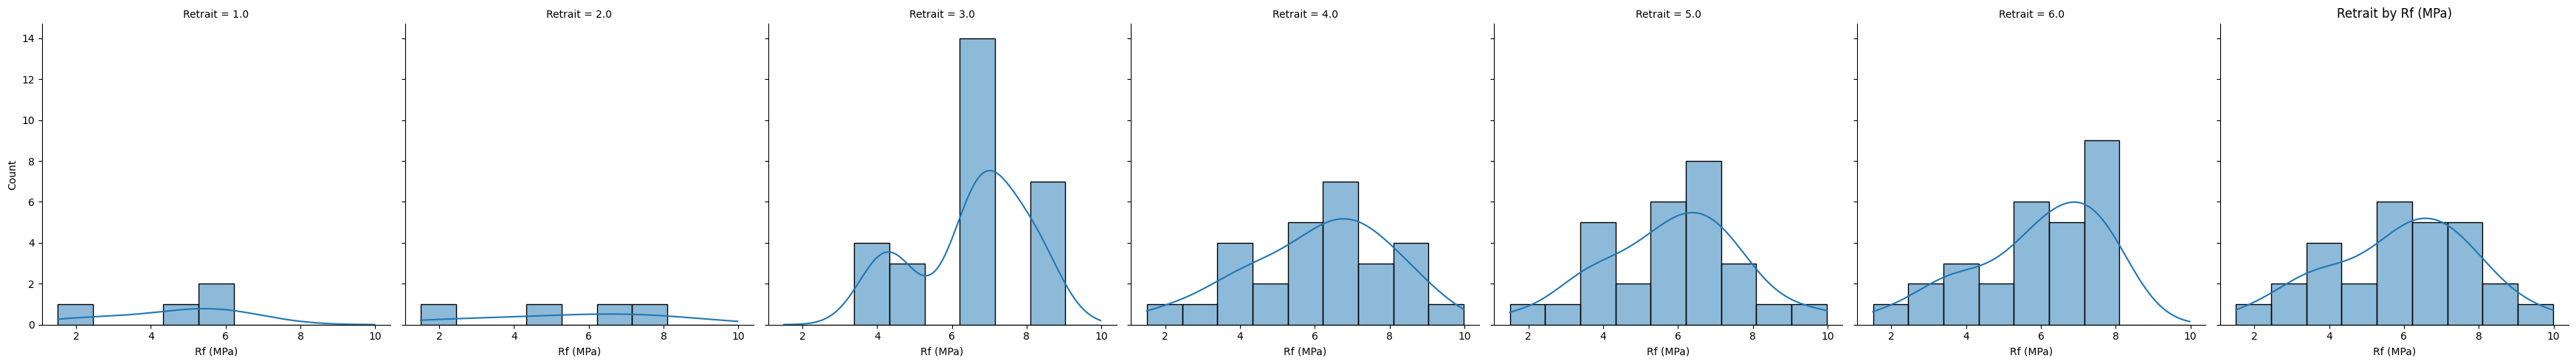

Coef.absorcion t=1 (%) Fibre 1 has 3 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

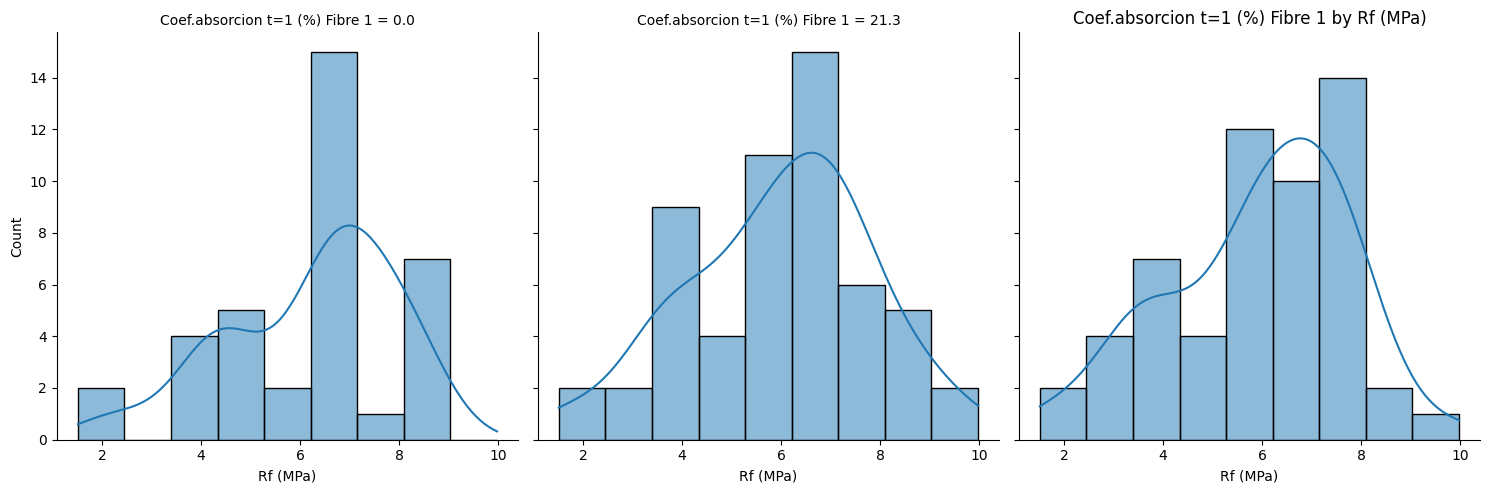

Coef.absorcion t=5 (%) Fibre 1 has 3 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

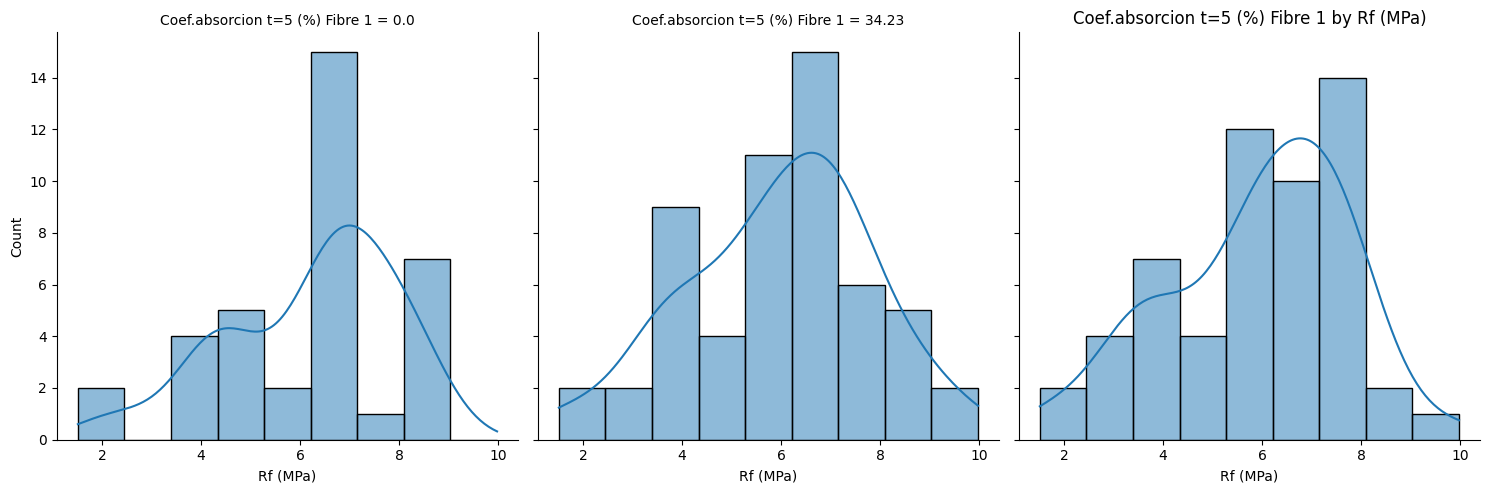

Coef.absorcion t=2880 (%) Fibre 1 has 3 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

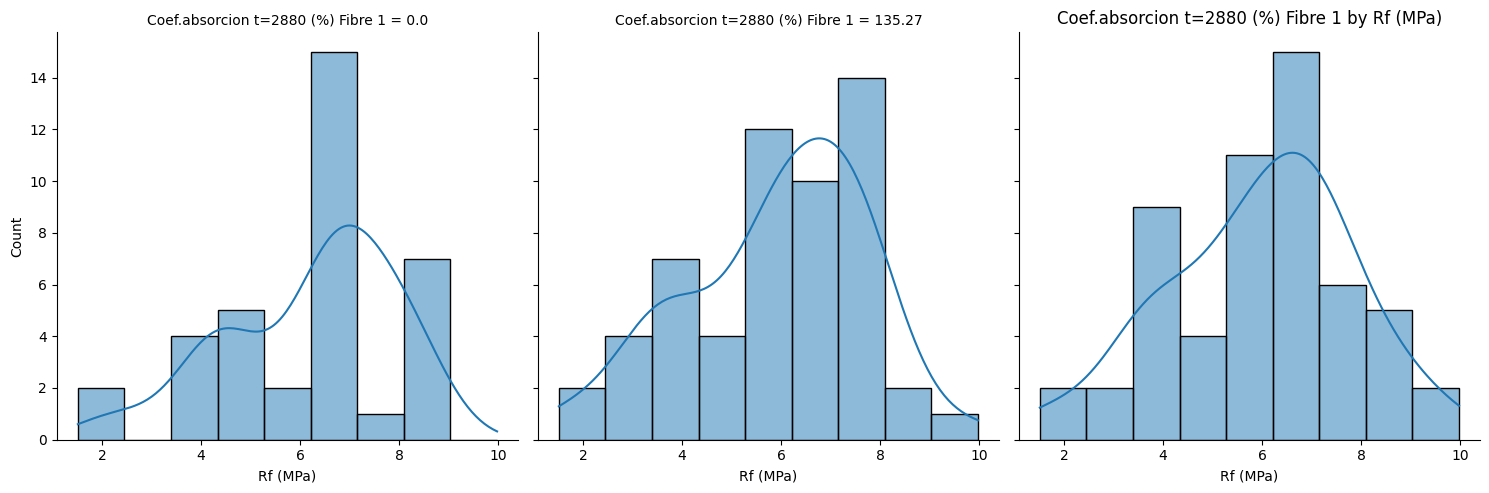

Coef.absorcion t=1 (%) Fibre 2 has 3 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

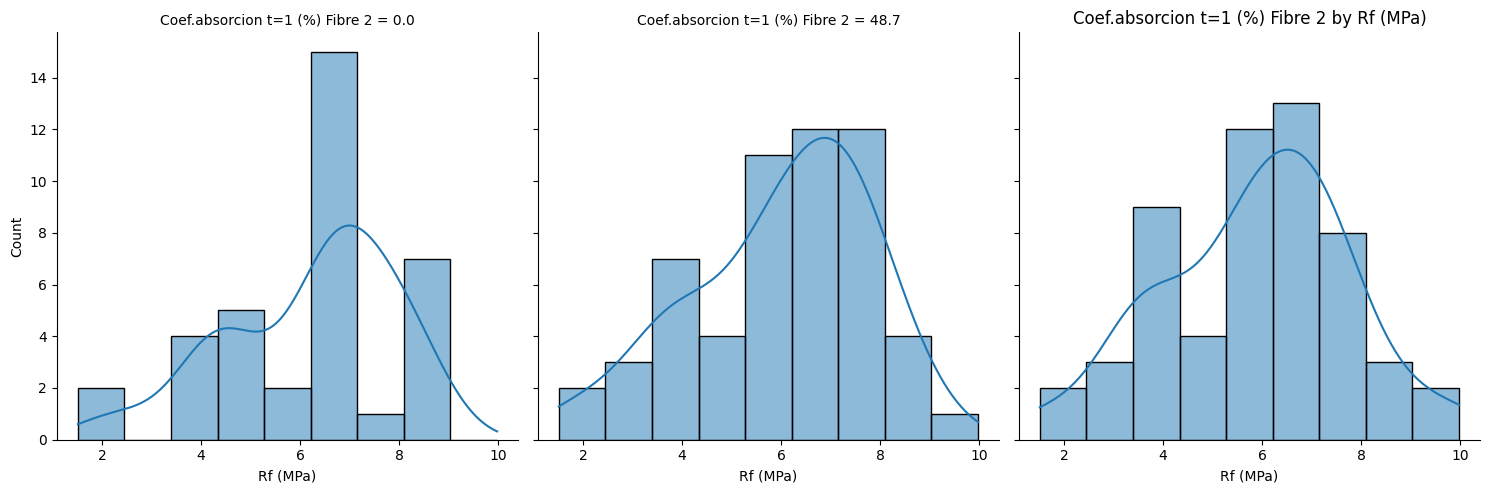

Coef.absorcion t=5 (%) Fibre 2 has 3 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

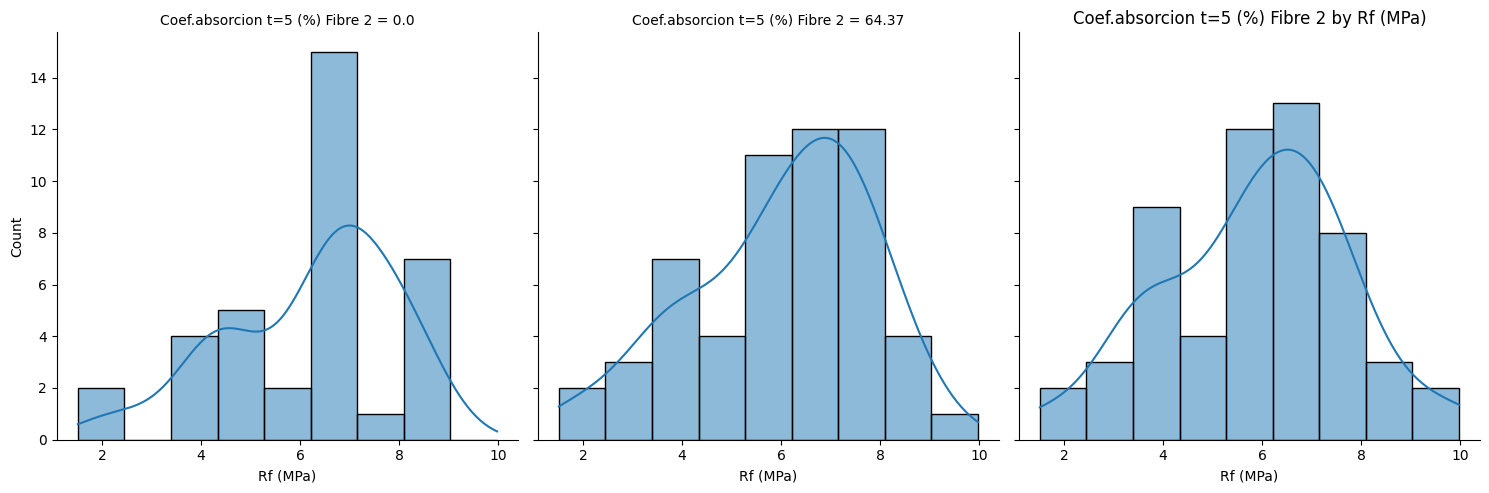

Coef.absorcion t=2880 (%) Fibre 2 has 3 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

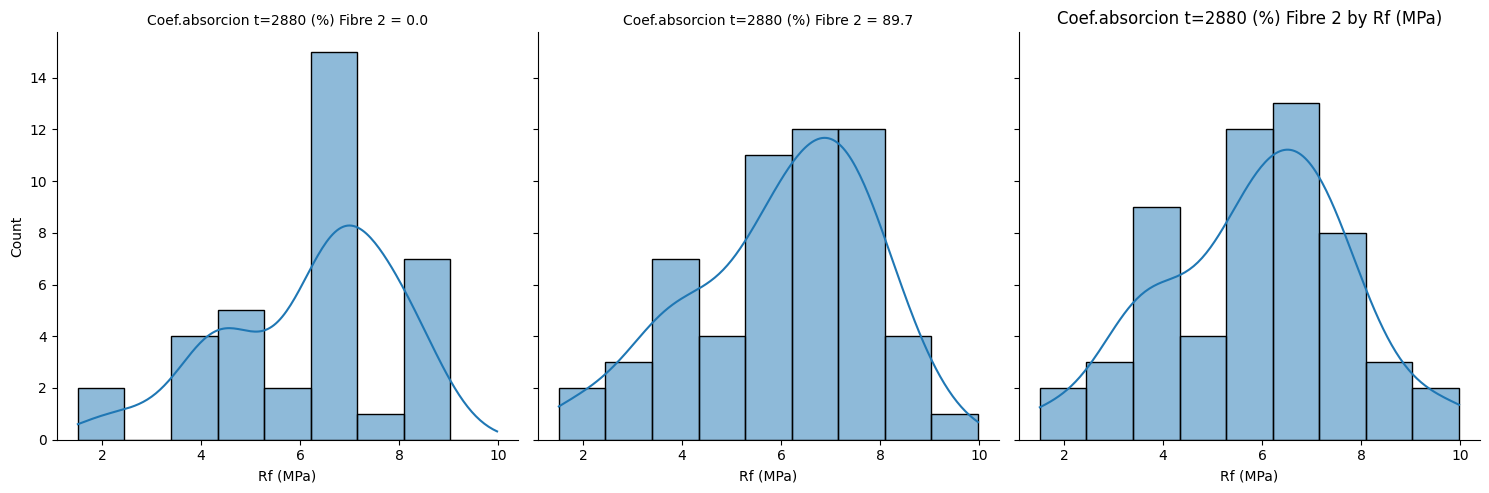

is_temoin has 2 distinct values, distribution by Rf (MPa):


<Figure size 1000x400 with 0 Axes>

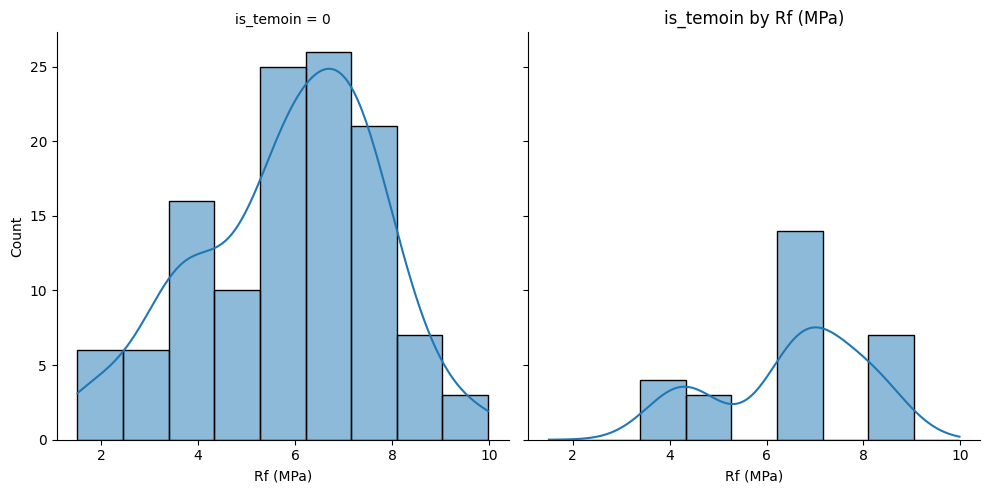

In [6]:
numerical_columns_with_min_distinct_values = [col for col in numerical_columns if data[col].nunique() < 15]
for column in numerical_columns_with_min_distinct_values:
    print(f'{column} has {data[column].nunique()} distinct values, distribution by {target}:')
    plt.figure(figsize=(10, 4))
    sns.displot(data=data, x=target, col=column, kde=True)
    plt.title(f'{column} by {target}')
    plt.show()

## 3.3 Linear / Non-linear Relationships

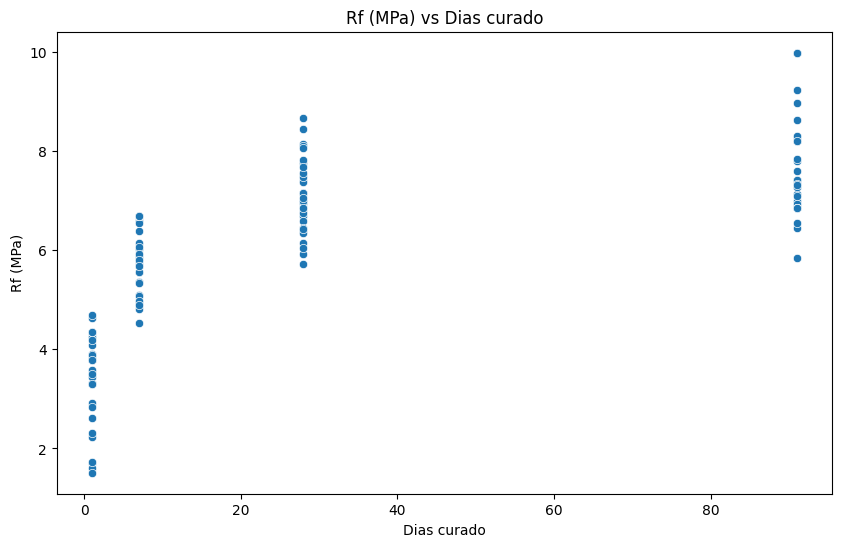

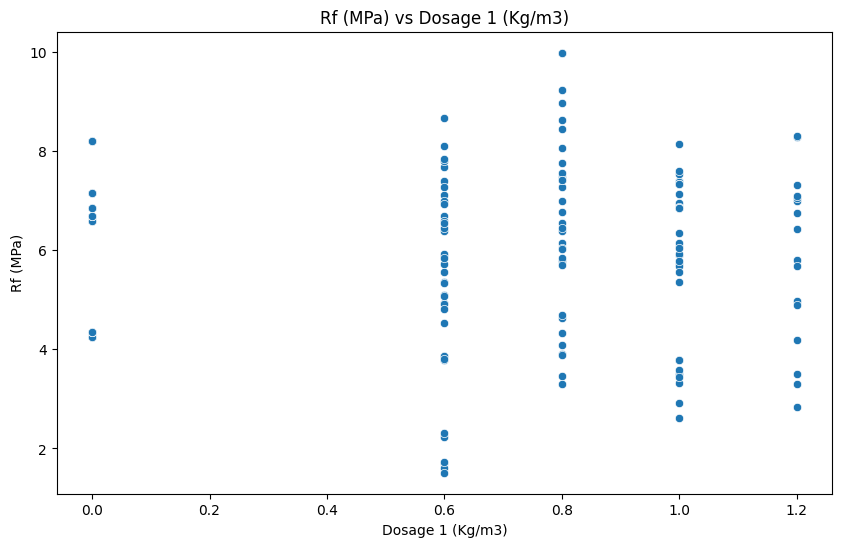

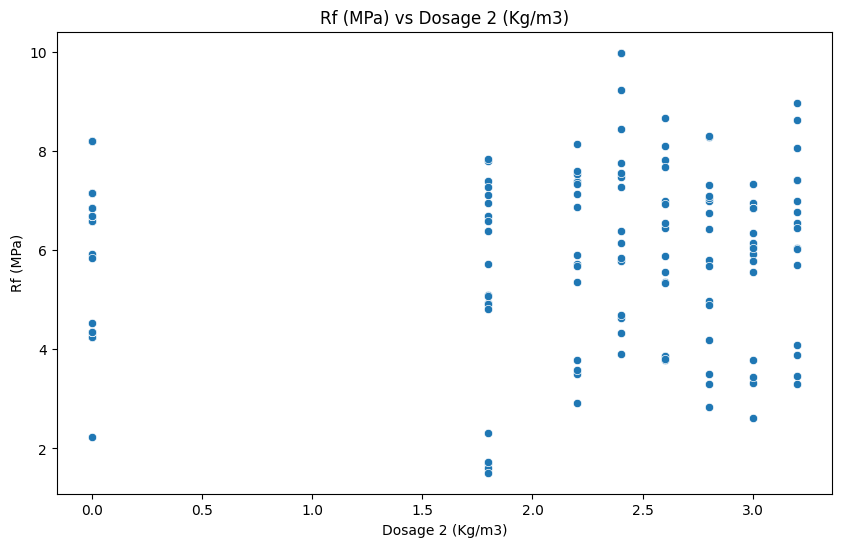

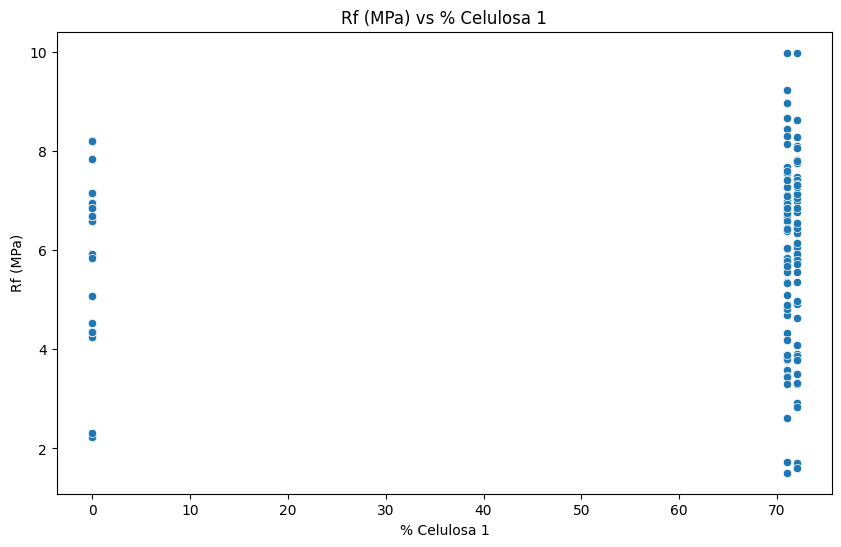

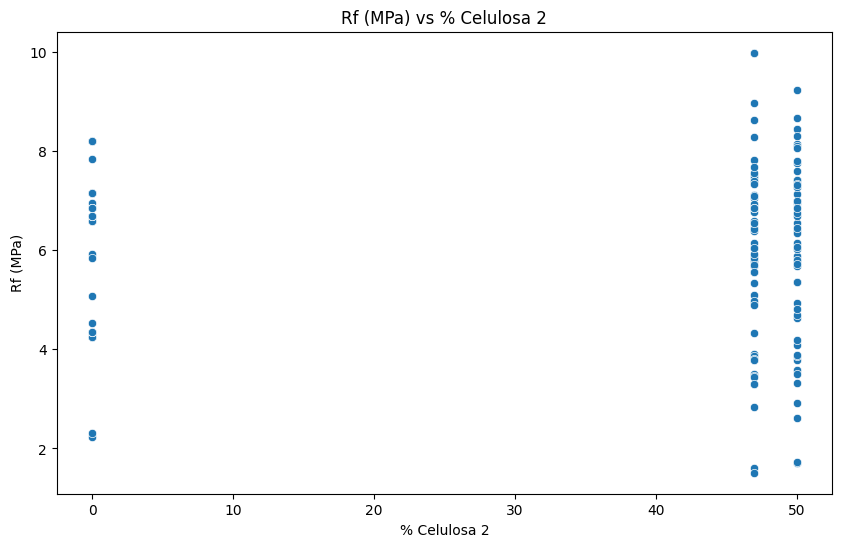

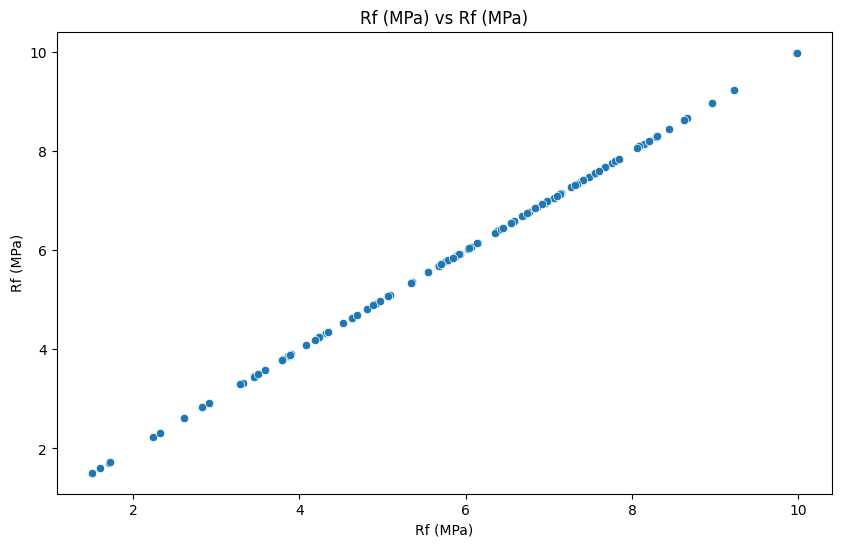

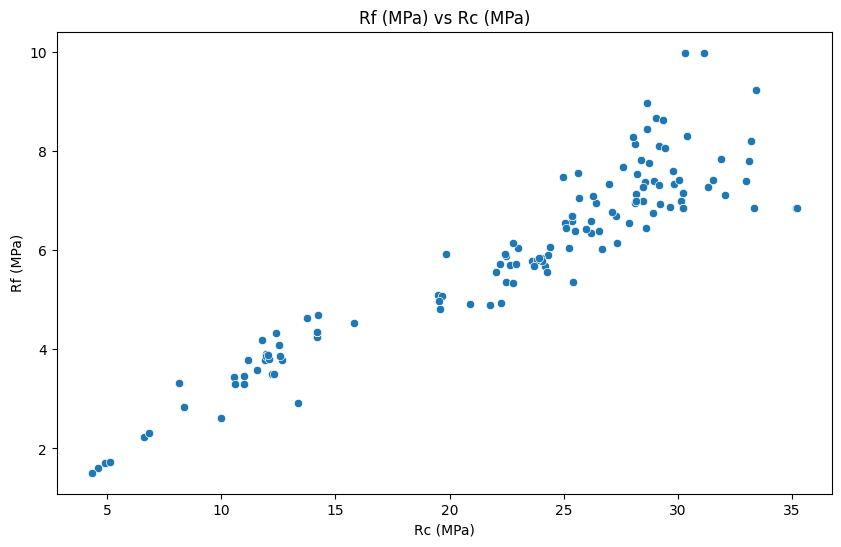

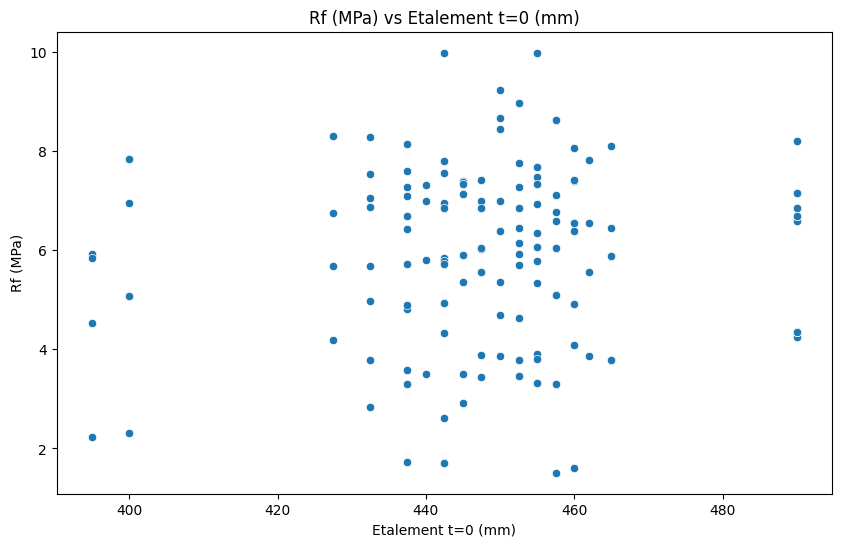

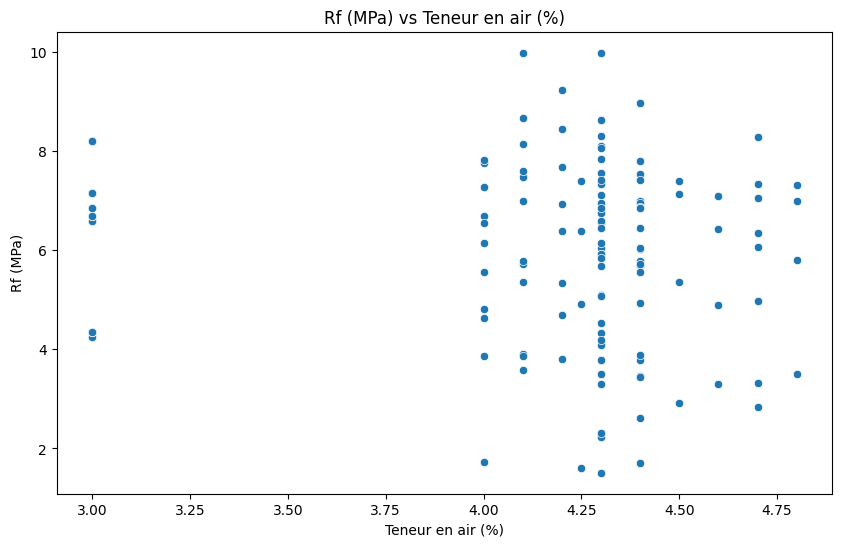

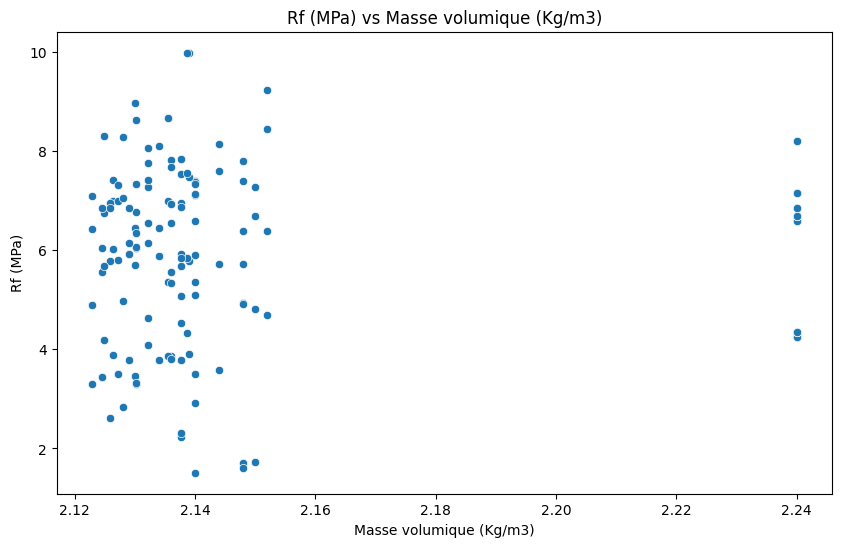

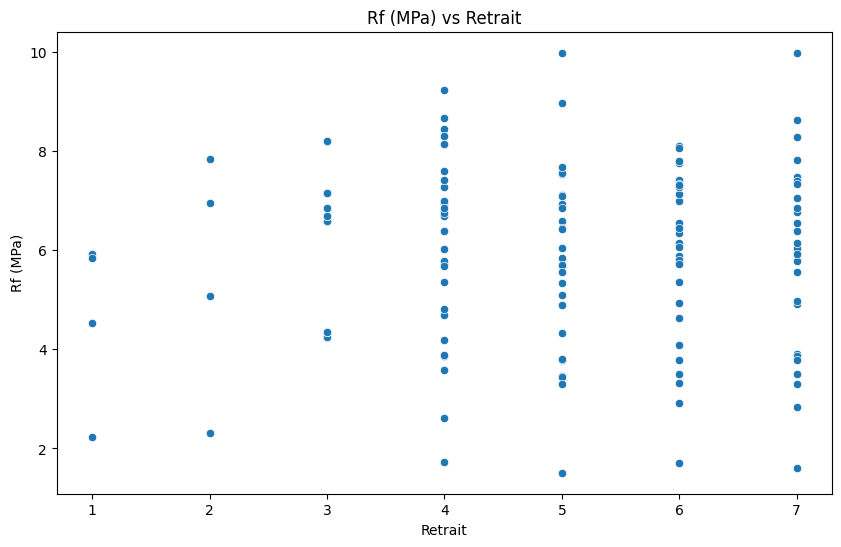

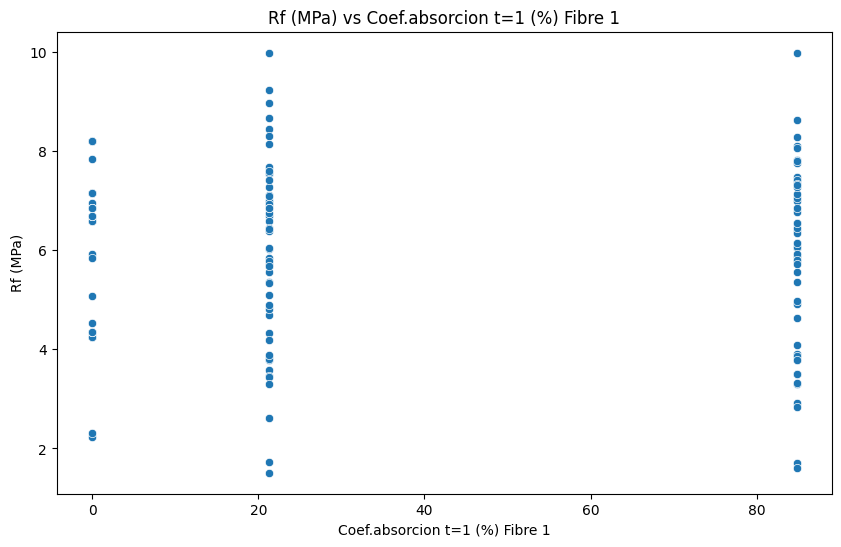

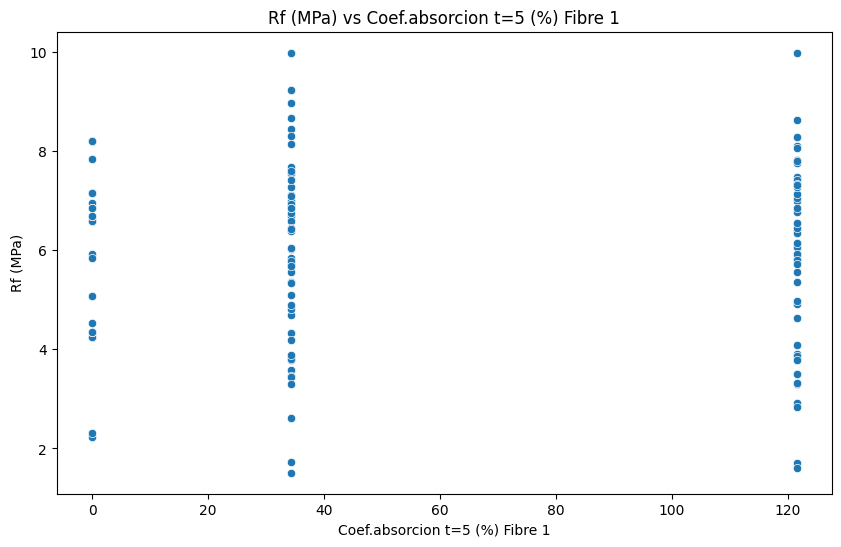

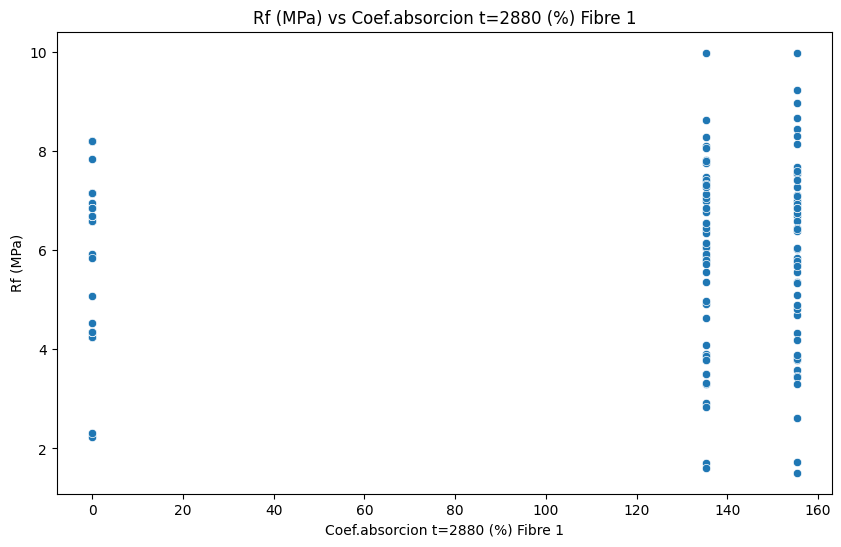

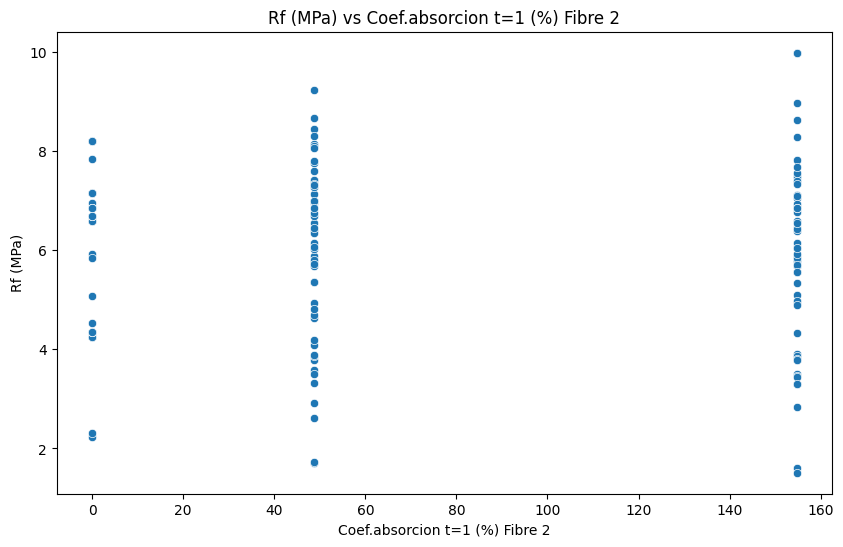

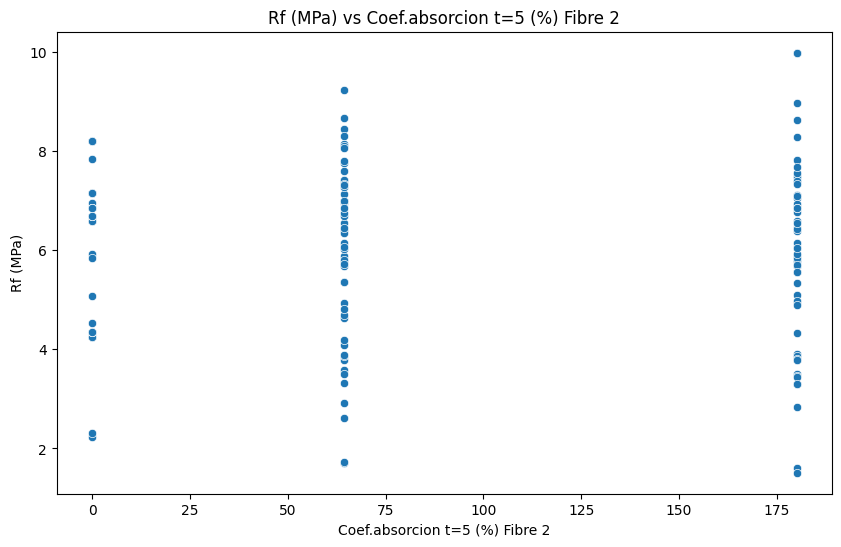

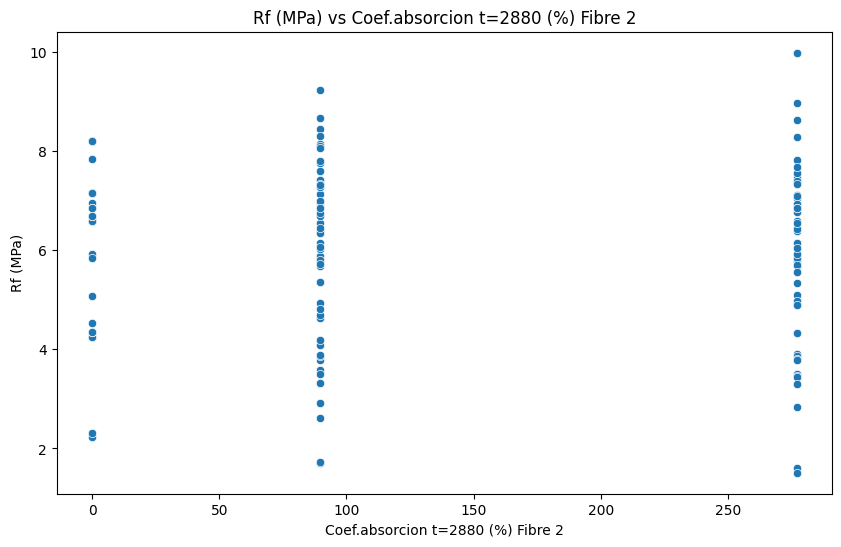

In [7]:
#scatter plots for numerical features vs target scatter plots en fr : nuage de points
cols_to_plot = [col for col in numerical_columns if col not in ['is_temoin'] and 'MEB' not in col]
for column in cols_to_plot:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=data[column], y=data[target])
    plt.title(f'{target} vs {column}')
    plt.xlabel(column)
    plt.ylabel(target)
    plt.show()

<p>After analysing the correlation heatmap, scatter plots (to assess the linearity or non-linearity of relationships) and the distribution of the target variable against other features, Dias curado emerges as the most correlated variable with the target (Rc or Rf), with a Pearson coefficient of 0.71. The remaining numerical features show weaker correlations; however, a non-linear model may still extract relevant information from them, particularly given the distributional patterns visible between these variables and target.</p>

## 3.4 Distribution of the Target Variable Across Categorical Modalities

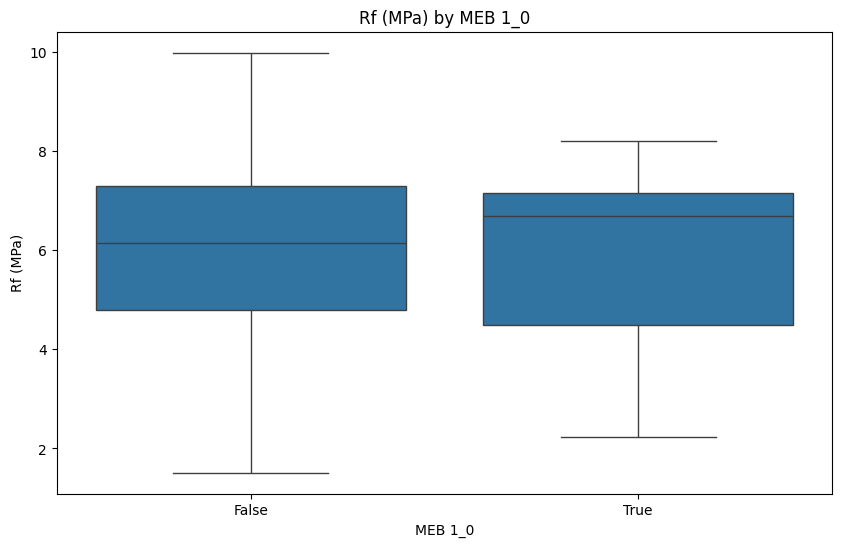

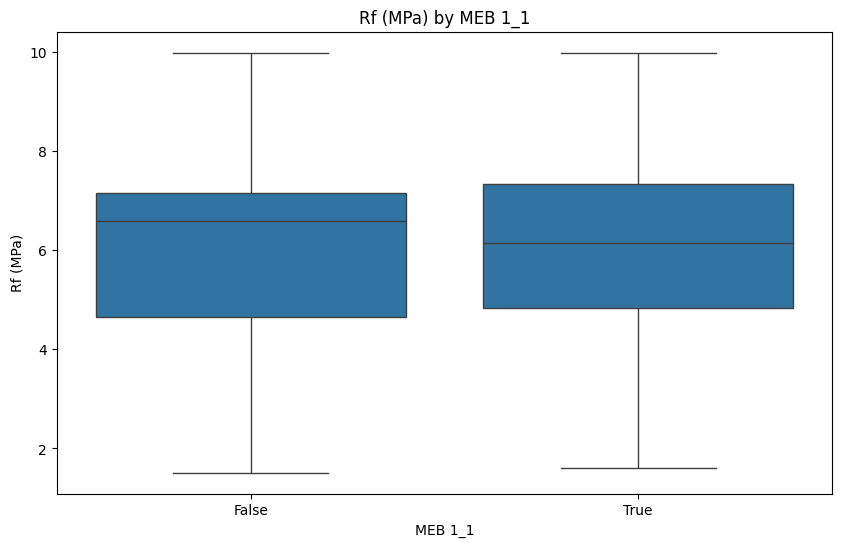

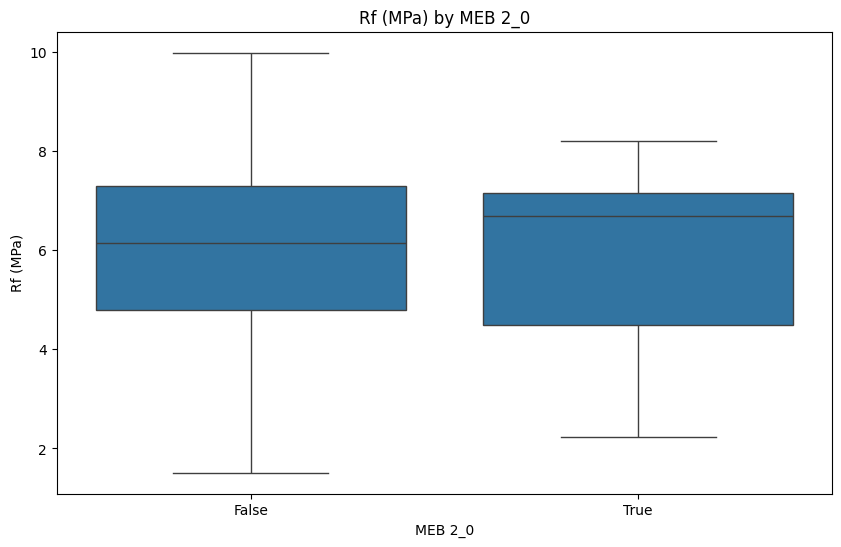

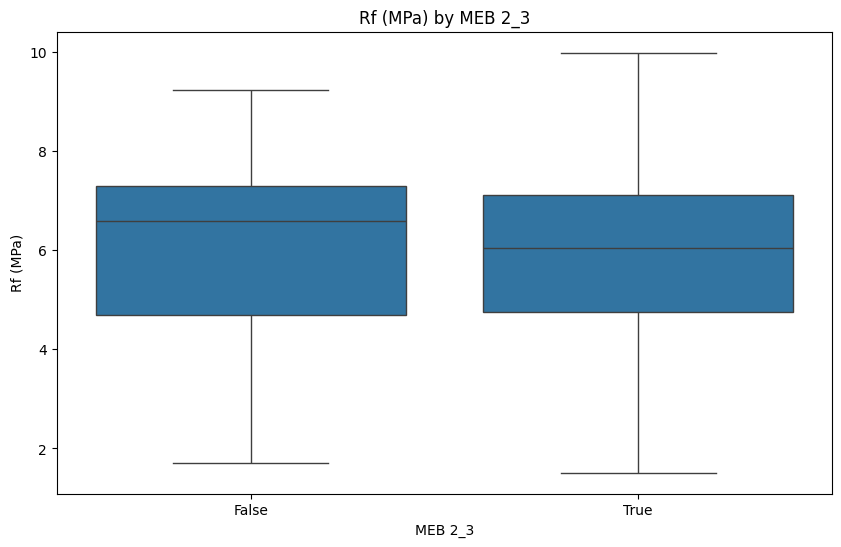

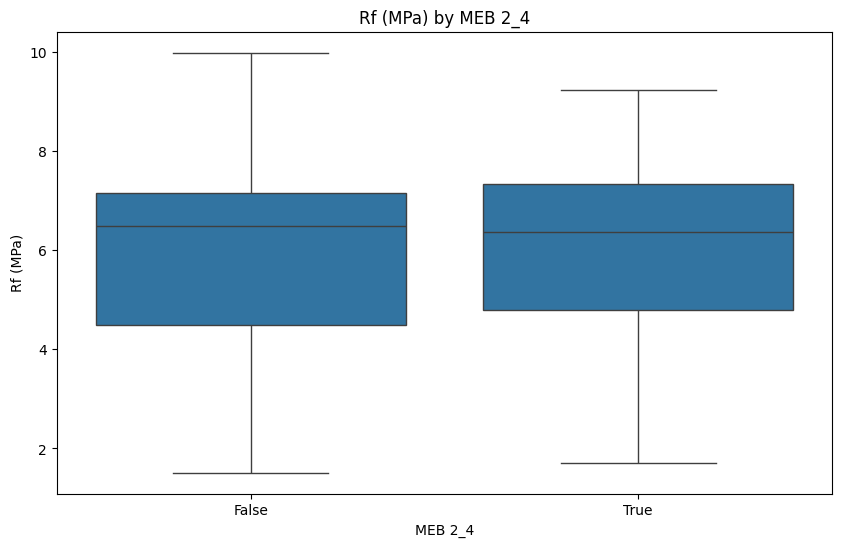

In [8]:
for column in ['MEB 1_0', 'MEB 1_1', 'MEB 2_0', 'MEB 2_3', 'MEB 2_4']:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=data[column], y=data[target])
    plt.title(f'{target} by {column}')
    plt.show()

<p></p>

## 4. Feature Selection and Consistency

<p style="color: grey;">
The column <strong>Rf (MPa) or Rc (Mpa)</strong> depending on the target value is removed to prevent data leakage. Flexural strength and compressive strength are measured simultaneously during the same mechanical test, making them strongly correlated features (r = 0.9388). Keeping Rf as a predictor would give the model information that is unavailable at inference time in a real-world scenario, rendering the prediction of Rc practically meaningless.
</p>

In [11]:
if(target == rc_target):
    print(data[rf_target].corr(data[rc_target]))
    data.drop(rf_target, axis=1, inplace=True)
else: 
    print(data[rc_target].corr(data[rc_target]))
    data.drop(rc_target, axis=1, inplace=True)

1.0


<p style="color: grey;">
The <strong>ID</strong> column is also dropped as it is a technical identifier with no predictive value for the model.
</p>

In [12]:
data.drop('ID', axis=1, inplace=True)

## 6. CSV Export

In [13]:
# export to csv
data.to_csv(f"../data/{file_name}.csv", index=False)